In [1]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

In [5]:
data = pd.read_csv('IMDB_Dataset.csv')
data['sentiment'] = data['sentiment'].map({'positive':1, 'negative':0})

In [6]:
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(data['review'])

sequences = tokenizer.texts_to_sequences(data['review'])
x = pad_sequences(sequences, maxlen=200)
y = data['sentiment'].values

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(200,)),
    tf.keras.layers.Embedding(10000, 64),
    tf.keras.layers.SimpleRNN(64),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    epochs=3,
                    batch_size=64,
                    validation_data=(x_test, y_test))

Epoch 1/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 53ms/step - accuracy: 0.7007 - loss: 0.5610 - val_accuracy: 0.7613 - val_loss: 0.4978
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.7567 - loss: 0.5009 - val_accuracy: 0.7460 - val_loss: 0.5173
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.8442 - loss: 0.3680 - val_accuracy: 0.8196 - val_loss: 0.4091


In [9]:
loss, accuracy = model.evaluate(x_test, y_test)
print("RNN Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8196 - loss: 0.4091
RNN Accuracy: 0.819599986076355


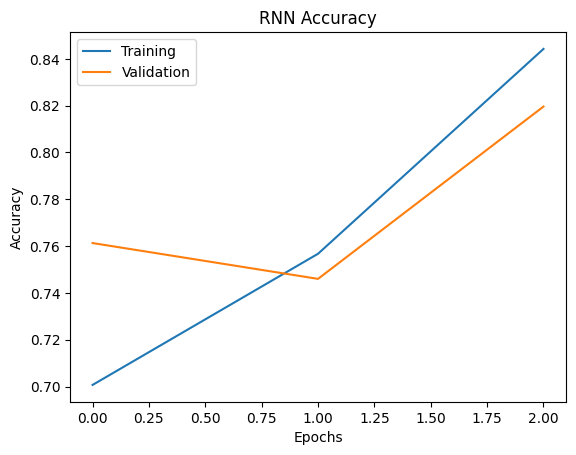

In [10]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title("RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [11]:
predictions = model.predict(x_test[:5])

for i in range(5):
    print("Actual:", "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", "Positive" if predictions[i][0] >= 0.5 else "Negative")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step
Actual: Positive
Predicted: Positive
Actual: Positive
Predicted: Positive
Actual: Negative
Predicted: Negative
Actual: Positive
Predicted: Positive
Actual: Negative
Predicted: Negative
